# Tuần 05 — Khái quát dữ liệu (1/7)

**UET.MAT1052 — Xác suất thống kê**  
**Hoàng Thị Điệp · Nghiêm Nguyễn Việt Dũng · Lê Thị Hường**  
*Khoa Công nghệ Thông tin (VNU-UET-FIT)*

## Notebook minh họa

### Nền tảng xác suất, xác suất có điều kiện và Bayes

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 2026
pd.set_option("display.precision", 4)


# 5. Quay lại nghịch lý De Méré

## 5.1. Xác suất lý thuyết bằng biến cố đối

Trò 1:

$$P(B_1)=1-\left(\frac56\right)^4.$$

Trò 2:

$$P(B_2)=1-\left(\frac{35}{36}\right)^{24}.$$


In [ ]:
p1_theory = 1 - (5/6)**4
p2_theory = 1 - (35/36)**24

print(f"P(thắng trò 1) = {p1_theory:.6f}")
print(f"P(thắng trò 2) = {p2_theory:.6f}")
print(f"So với 1/2: trò 1 {p1_theory-0.5:+.4f}; trò 2 {p2_theory-0.5:+.4f}")


P(thắng trò 1) = 0.517747
P(thắng trò 2) = 0.491404
So với 1/2: trò 1 +0.0177; trò 2 -0.0086


## 5.2. Mô phỏng De Méré — xác suất thực nghiệm hội tụ về lý thuyết

Thay vì chỉ mô phỏng một lần, ta theo dõi tỷ lệ thắng tích lũy theo số ván. Đường thực nghiệm được so sánh trực tiếp với giá trị lý thuyết.


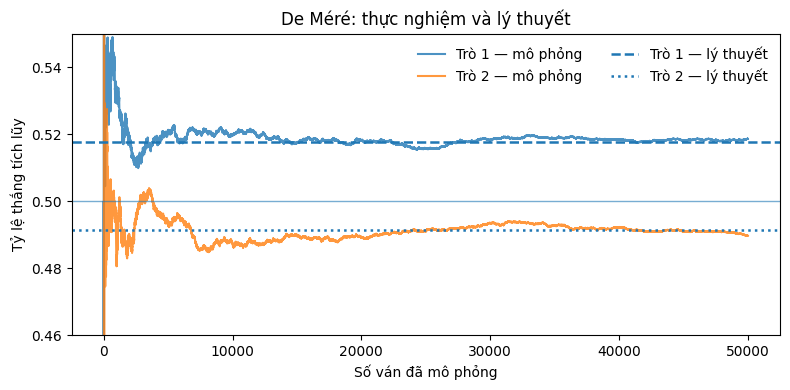

Sau 50,000 ván: trò 1 = 0.51868, trò 2 = 0.48974


In [ ]:
rng = np.random.default_rng(SEED + 5)
n_games = 50_000

game1 = rng.integers(1, 7, size=(n_games, 4))
game2 = rng.integers(1, 7, size=(n_games, 24, 2))

wins1 = (game1 == 6).any(axis=1).astype(int)
wins2 = (game2 == 6).all(axis=2).any(axis=1).astype(int)

running1 = np.cumsum(wins1) / np.arange(1, n_games + 1)
running2 = np.cumsum(wins2) / np.arange(1, n_games + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(running1, label="Trò 1 — mô phỏng", alpha=0.8)
ax.plot(running2, label="Trò 2 — mô phỏng", alpha=0.8)
ax.axhline(p1_theory, linestyle="--", linewidth=1.8, label="Trò 1 — lý thuyết")
ax.axhline(p2_theory, linestyle=":", linewidth=1.8, label="Trò 2 — lý thuyết")
ax.axhline(0.5, linewidth=1, alpha=0.6)
ax.set_xlabel("Số ván đã mô phỏng")
ax.set_ylabel("Tỷ lệ thắng tích lũy")
ax.set_ylim(0.46, 0.55)
ax.legend(frameon=False, ncol=2)
ax.set_title("De Méré: thực nghiệm và lý thuyết")
plt.tight_layout()
plt.show()

print(f"Sau {n_games:,} ván: trò 1 = {wins1.mean():.5f}, trò 2 = {wins2.mean():.5f}")


In [ ]:
# Biểu đồ slide “Kết quả mô phỏng De Méré”

p1_sim = wins1.mean()
p2_sim = wins2.mean()
p_theory = [1 - (5/6)**4, 1 - (35/36)**24]

plt.figure(figsize=(6.5, 2.7))
plt.bar(["Trò 1", "Trò 2"], [p1_sim, p2_sim],
        color="#4C78A8", label="Mô phỏng")
plt.scatter(["Trò 1", "Trò 2"], p_theory,
            color="#E45756", zorder=3, label="Lý thuyết")
plt.axhline(0.5, color="gray", linestyle="--")
plt.ylabel("Xác suất thắng")
plt.ylim(0.45, 0.54)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()
